<center>
    <p style="color: red; font-size: 20px;">Tên: Lê Thiên Hạo</p>
</center>
<center>
    <p style="color: red; font-size: 20px;">MSSV: 089206010393</p>
</center>

## 1. Chuẩn bị dữ liệu
Clone repository chính thức của bộ dataset **FMA (Free Music Archive)** — chứa code tiện ích (`utils.py`) để load metadata và audio.

In [1]:
!git clone https://github.com/mdeff/fma.git

Cloning into 'fma'...
remote: Enumerating objects: 823, done.
remote: Counting objects: 100% (822/822), done.
remote: Compressing objects: 100% (287/287), done.
remote: Total 823 (delta 532), reused 621 (delta 527), pack-reused 1 (from 1)
Receiving objects: 100% (823/823), 4.08 MiB | 30.48 MiB/s, done.
Resolving deltas: 100% (532/532), done.


Tải file `fma_small.zip` — phiên bản rút gọn của dataset (~8000 bài, 8 thể loại cân bằng), phù hợp để thử nghiệm nhanh mà không cần tải toàn bộ ~100GB của bản đầy đủ.

In [4]:
!curl -O https://os.unil.cloud.switch.ch/fma/fma_small.zip

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 7323M  100 7323M    0     0  30.2M      0  0:04:02  0:04:02 --:--:-- 30.1M1M      0  0:04:40  0:00:09  0:04:31 30.4M7M    0     0  28.8M      0  0:04:13  0:00:26  0:03:47 30.8M7M      0  0:04:06  0:01:15  0:02:51 30.2M8M      0  0:04:05  0:01:20  0:02:45 30.7M


Giải nén dữ liệu audio (.mp3) vào thư mục làm việc.

In [5]:
!unzip fma_small.zip -d /kaggle/working/fma/data

Archive:  fma_small.zip
 bunzipping: /kaggle/working/fma/data/fma_small/README.txt  
 bunzipping: /kaggle/working/fma/data/fma_small/checksums  
 bunzipping: /kaggle/working/fma/data/fma_small/000/000002.mp3  
 bunzipping: /kaggle/working/fma/data/fma_small/000/000005.mp3  
 bunzipping: /kaggle/working/fma/data/fma_small/000/000010.mp3  
 bunzipping: /kaggle/working/fma/data/fma_small/000/000140.mp3  
 bunzipping: /kaggle/working/fma/data/fma_small/000/000141.mp3  
 bunzipping: /kaggle/working/fma/data/fma_small/000/000148.mp3  
 bunzipping: /kaggle/working/fma/data/fma_small/000/000182.mp3  
 bunzipping: /kaggle/working/fma/data/fma_small/000/000190.mp3  
 bunzipping: /kaggle/working/fma/data/fma_small/000/000193.mp3  
 bunzipping: /kaggle/working/fma/data/fma_small/000/000194.mp3  
 bunzipping: /kaggle/working/fma/data/fma_small/000/000197.mp3  
 bunzipping: /kaggle/working/fma/data/fma_small/000/000200.mp3  
 bunzipping: /kaggle/working/fma/data/fma_small/000/000203.mp3  
 bunzippin

Tạo file `.env` rỗng — nơi sẽ lưu các biến môi trường (đường dẫn thư mục) để notebook đọc lại về sau, tránh phải gõ path tay nhiều lần.

In [6]:
!touch /kaggle/working/fma/.env

Khai báo biến `ROOT` làm **folder gốc cố định** cho toàn bộ notebook. Mọi đường dẫn khác (audio, metadata) đều được suy ra từ biến này — chỉ cần đổi `ROOT` một chỗ là áp dụng cho toàn bộ code phía sau.

In [7]:
import os

ROOT = '/kaggle/working/fma'  # đổi thành path bạn muốn làm gốc
AUDIO_DIR = os.path.join(ROOT, 'fma_small')

os.chdir(ROOT)  # chuyển working directory về đây luôn
print('Working dir:', os.getcwd())

Working dir: /kaggle/working/fma


Ghi các đường dẫn vào file `.env` bằng magic command `%%writefile`, để các cell sau có thể đọc lại qua `os.environ` mà không cần hardcode.

In [8]:
%%writefile /kaggle/working/fma/.env
AUDIO_DIR=/kaggle/working/fma/data/fma_small

Overwriting /kaggle/working/fma/.env


Tải file `fma_metadata.zip` — chứa các bảng thông tin: tên bài hát, nghệ sĩ, thể loại (genre), và các đặc trưng âm thanh (features) đã được trích xuất sẵn.

In [11]:
!curl -O https://os.unil.cloud.switch.ch/fma/fma_metadata.zip

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  341M  100  341M    0     0  30.5M      0  0:00:11  0:00:11 --:--:-- 34.5M


Giải nén metadata vào thư mục dữ liệu.

In [13]:
!unzip /kaggle/working/fma/fma_metadata.zip -d /kaggle/working/fma/data

Archive:  /kaggle/working/fma/fma_metadata.zip
 bunzipping: /kaggle/working/fma/data/fma_metadata/README.txt  
 bunzipping: /kaggle/working/fma/data/fma_metadata/checksums  
 bunzipping: /kaggle/working/fma/data/fma_metadata/not_found.pickle  
 bunzipping: /kaggle/working/fma/data/fma_metadata/raw_genres.csv  
 bunzipping: /kaggle/working/fma/data/fma_metadata/raw_albums.csv  
 bunzipping: /kaggle/working/fma/data/fma_metadata/raw_artists.csv  
 bunzipping: /kaggle/working/fma/data/fma_metadata/raw_tracks.csv  
 bunzipping: /kaggle/working/fma/data/fma_metadata/tracks.csv  
 bunzipping: /kaggle/working/fma/data/fma_metadata/genres.csv  
 bunzipping: /kaggle/working/fma/data/fma_metadata/raw_echonest.csv  
 bunzipping: /kaggle/working/fma/data/fma_metadata/echonest.csv  
 bunzipping: /kaggle/working/fma/data/fma_metadata/features.csv  


## 2. Khám phá dữ liệu (EDA)
Import các thư viện cần thiết: `librosa` (xử lý âm thanh), `numpy`/`pandas` (xử lý dữ liệu), `IPython.display` (nghe thử audio ngay trong notebook), và load các bảng metadata (`tracks`, `genres`, `features`, `echonest`) bằng hàm `utils.load()` có sẵn trong repo FMA.

In [14]:
%matplotlib inline

import os

import IPython.display as ipd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as skl
import sklearn.utils, sklearn.preprocessing, sklearn.decomposition, sklearn.svm
import librosa
import librosa.display

import utils

plt.rcParams['figure.figsize'] = (17, 5)

Đọc đường dẫn thư mục audio (`AUDIO_DIR`) từ file `.env` đã ghi ở bước trước.

In [15]:
# Directory where mp3 are stored.
AUDIO_DIR = os.environ.get('AUDIO_DIR')

# Load metadata and features.
tracks = utils.load('data/fma_metadata/tracks.csv')
genres = utils.load('data/fma_metadata/genres.csv')
features = utils.load('data/fma_metadata/features.csv')
echonest = utils.load('data/fma_metadata/echonest.csv')

np.testing.assert_array_equal(features.index, tracks.index)
assert echonest.index.isin(tracks.index).all()

tracks.shape, genres.shape, features.shape, echonest.shape

((106574, 52), (163, 4), (106574, 518), (13129, 249))

Xem nhanh cấu trúc dữ liệu của các bảng `track`, `album`, `artist` — mỗi bảng chứa thông tin metadata tương ứng cho từng bài hát.

In [16]:
ipd.display(tracks['track'].head())
ipd.display(tracks['album'].head())
ipd.display(tracks['artist'].head())
ipd.display(tracks['set'].head())

,bit_rate,comments,composer,date_created,date_recorded,duration,favorites,genre_top,genres,genres_all,information,interest,language_code,license,listens,lyricist,number,publisher,tags,title
track_id,,,,,,,,,,,,,,,,,,,,
2,256000,0,NaN,2008-11-26 01:48:12,2008-11-26,168,2,Hip-Hop,[21],[21],NaN,4656,en,Attribution-NonCommercial-ShareAlike 3.0 Inter...,1293,NaN,3,NaN,[],Food
3,256000,0,NaN,2008-11-26 01:48:14,2008-11-26,237,1,Hip-Hop,[21],[21],NaN,1470,en,Attribution-NonCommercial-ShareAlike 3.0 Inter...,514,NaN,4,NaN,[],Electric Ave
5,256000,0,NaN,2008-11-26 01:48:20,2008-11-26,206,6,Hip-Hop,[21],[21],NaN,1933,en,Attribution-NonCommercial-ShareAlike 3.0 Inter...,1151,NaN,6,NaN,[],This World
10,192000,0,Kurt Vile,2008-11-25 17:49:06,2008-11-26,161,178,Pop,[10],[10],NaN,54881,en,Attribution-NonCommercial-NoDerivatives (aka M...,50135,NaN,1,NaN,[],Freeway
20,256000,0,NaN,2008-11-26 01:48:56,2008-01-01,311,0,NaN,"[76, 103]","[17, 10, 76, 103]",NaN,978,en,Attribution-NonCommercial-NoDerivatives (aka M...,361,NaN,3,NaN,[],Spiritual Level


,comments,date_created,date_released,engineer,favorites,id,information,listens,producer,tags,title,tracks,type
track_id,,,,,,,,,,,,,
2,0,2008-11-26 01:44:45,2009-01-05,NaN,4,1,<p></p>,6073,NaN,[],AWOL - A Way Of Life,7,Album
3,0,2008-11-26 01:44:45,2009-01-05,NaN,4,1,<p></p>,6073,NaN,[],AWOL - A Way Of Life,7,Album
5,0,2008-11-26 01:44:45,2009-01-05,NaN,4,1,<p></p>,6073,NaN,[],AWOL - A Way Of Life,7,Album
10,0,2008-11-26 01:45:08,2008-02-06,NaN,4,6,NaN,47632,NaN,[],Constant Hitmaker,2,Album
20,0,2008-11-26 01:45:05,2009-01-06,NaN,2,4,"<p> ""spiritual songs"" from Nicky Cook</p>",2710,NaN,[],Niris,13,Album


,active_year_begin,active_year_end,associated_labels,bio,comments,date_created,favorites,id,latitude,location,longitude,members,name,related_projects,tags,website,wikipedia_page
track_id,,,,,,,,,,,,,,,,,
2,2006-01-01,NaT,NaN,"<p>A Way Of Life, A Collective of Hip-Hop from...",0,2008-11-26 01:42:32,9,1,40.058324,New Jersey,-74.405661,"Sajje Morocco,Brownbum,ZawidaGod,Custodian of ...",AWOL,The list of past projects is 2 long but every1...,[awol],http://www.AzillionRecords.blogspot.com,NaN
3,2006-01-01,NaT,NaN,"<p>A Way Of Life, A Collective of Hip-Hop from...",0,2008-11-26 01:42:32,9,1,40.058324,New Jersey,-74.405661,"Sajje Morocco,Brownbum,ZawidaGod,Custodian of ...",AWOL,The list of past projects is 2 long but every1...,[awol],http://www.AzillionRecords.blogspot.com,NaN
5,2006-01-01,NaT,NaN,"<p>A Way Of Life, A Collective of Hip-Hop from...",0,2008-11-26 01:42:32,9,1,40.058324,New Jersey,-74.405661,"Sajje Morocco,Brownbum,ZawidaGod,Custodian of ...",AWOL,The list of past projects is 2 long but every1...,[awol],http://www.AzillionRecords.blogspot.com,NaN
10,NaT,NaT,"Mexican Summer, Richie Records, Woodsist, Skul...","<p><span style=""font-family:Verdana, Geneva, A...",3,2008-11-26 01:42:55,74,6,NaN,NaN,NaN,"Kurt Vile, the Violators",Kurt Vile,NaN,"[philly, kurt vile]",http://kurtvile.com,NaN
20,1990-01-01,2011-01-01,NaN,<p>Songs written by: Nicky Cook</p>\n<p>VOCALS...,2,2008-11-26 01:42:52,10,4,51.895927,Colchester England,0.891874,Nicky Cook\n,Nicky Cook,NaN,"[instrumentals, experimental pop, post punk, e...",NaN,NaN


,split,subset
track_id,,
2,training,small
3,training,medium
5,training,small
10,training,small
20,training,large


Lọc ra tập con **`small`** (subset nhỏ) từ toàn bộ dataset — đây là tập dữ liệu chính sẽ dùng xuyên suốt notebook.

In [18]:
small = tracks[tracks['set', 'subset'] <= 'small']
small.shape

(8000, 52)

Lọc ra tập con **`medium`** để so sánh kích thước (không nhất thiết dùng cho phần sau, chỉ để tham khảo quy mô dataset).

In [19]:
medium = tracks[tracks['set', 'subset'] <= 'medium']
medium.shape

(25000, 52)

Thống kê số lượng thể loại nhạc (genre) cấp cao nhất (`top_level`) có trong dataset.

In [20]:
print('{} top-level genres'.format(len(genres['top_level'].unique())))
genres.loc[genres['top_level'].unique()].sort_values('#tracks', ascending=False)

16 top-level genres


,#tracks,parent,title,top_level
genre_id,,,,
38,38154,0,Experimental,38
15,34413,0,Electronic,15
12,32923,0,Rock,12
1235,14938,0,Instrumental,1235
10,13845,0,Pop,10
17,12706,0,Folk,17
21,8389,0,Hip-Hop,21
2,5271,0,International,2
4,4126,0,Jazz,4


Xem số lượng và loại đặc trưng âm thanh (`mfcc`, `chroma`, `spectral`...) đã được trích xuất sẵn cho mỗi bài hát trong bảng `features`.

In [21]:
print('{1} features for {0} tracks'.format(*features.shape))
columns = ['mfcc', 'chroma_cens', 'tonnetz', 'spectral_contrast']
columns.append(['spectral_centroid', 'spectral_bandwidth', 'spectral_rolloff'])
columns.append(['rmse', 'zcr'])
for column in columns:
    ipd.display(features[column].head().style.format('{:.2f}'))

518 features for 106574 tracks


Xem thông tin từ bảng `echonest` — bộ đặc trưng âm thanh bổ sung do Echo Nest (Spotify) cung cấp cho một phần nhỏ dataset.

In [22]:
print('{1} features for {0} tracks'.format(*echonest.shape))
ipd.display(echonest['echonest', 'metadata'].head())
ipd.display(echonest['echonest', 'audio_features'].head())
ipd.display(echonest['echonest', 'social_features'].head())
ipd.display(echonest['echonest', 'ranks'].head())

249 features for 13129 tracks


,album_date,album_name,artist_latitude,artist_location,artist_longitude,artist_name,release
track_id,,,,,,,
2,NaN,NaN,32.6783,"Georgia, US",-83.2230,AWOL,AWOL - A Way Of Life
3,NaN,NaN,32.6783,"Georgia, US",-83.2230,AWOL,AWOL - A Way Of Life
5,NaN,NaN,32.6783,"Georgia, US",-83.2230,AWOL,AWOL - A Way Of Life
10,2008-03-11,Constant Hitmaker,39.9523,"Philadelphia, PA, US",-75.1624,Kurt Vile,Constant Hitmaker
134,NaN,NaN,32.6783,"Georgia, US",-83.2230,AWOL,AWOL - A Way Of Life


,acousticness,danceability,energy,instrumentalness,liveness,speechiness,tempo,valence
track_id,,,,,,,,
2,0.416675,0.675894,0.634476,0.010628,0.177647,0.159310,165.922,0.576661
3,0.374408,0.528643,0.817461,0.001851,0.105880,0.461818,126.957,0.269240
5,0.043567,0.745566,0.701470,0.000697,0.373143,0.124595,100.260,0.621661
10,0.951670,0.658179,0.924525,0.965427,0.115474,0.032985,111.562,0.963590
134,0.452217,0.513238,0.560410,0.019443,0.096567,0.525519,114.290,0.894072


,artist_discovery,artist_familiarity,artist_hotttnesss,song_currency,song_hotttnesss
track_id,,,,,
2,0.388990,0.386740,0.406370,0.000000,0.000000
3,0.388990,0.386740,0.406370,0.000000,0.000000
5,0.388990,0.386740,0.406370,0.000000,0.000000
10,0.557339,0.614272,0.798387,0.005158,0.354516
134,0.388990,0.386740,0.406370,0.000000,0.000000


,artist_discovery_rank,artist_familiarity_rank,artist_hotttnesss_rank,song_currency_rank,song_hotttnesss_rank
track_id,,,,,
2,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN
10,2635.0,2544.0,397.0,115691.0,67609.0
134,NaN,NaN,NaN,NaN,NaN


Xem chi tiết các đặc trưng "temporal" (theo thời gian) trong `echonest`, và thử truy xuất thông tin của 1 bài hát cụ thể (track_id = 2).

,000,001,002,003,004,005,006,007,008,009,...,214,215,216,217,218,219,220,221,222,223
track_id,,,,,,,,,,,,,,,,,,,,,
2,0.877233,0.588911,0.354243,0.295090,0.298413,0.309430,0.304496,0.334579,0.249495,0.259656,...,-1.992303,6.805694,0.233070,0.192880,0.027455,0.06408,3.67696,3.61288,13.316690,262.929749
3,0.534429,0.537414,0.443299,0.390879,0.344573,0.366448,0.419455,0.747766,0.460901,0.392379,...,-1.582331,8.889308,0.258464,0.220905,0.081368,0.06413,6.08277,6.01864,16.673548,325.581085
5,0.548093,0.720192,0.389257,0.344934,0.361300,0.402543,0.434044,0.388137,0.512487,0.525755,...,-2.288358,11.527109,0.256821,0.237820,0.060122,0.06014,5.92649,5.86635,16.013849,356.755737
10,0.311404,0.711402,0.321914,0.500601,0.250963,0.321316,0.734250,0.325188,0.373012,0.235840,...,-3.662988,21.508228,0.283352,0.267070,0.125704,0.08082,8.41401,8.33319,21.317064,483.403809
134,0.610849,0.569169,0.428494,0.345796,0.376920,0.460590,0.401371,0.449900,0.428946,0.446736,...,-1.452696,2.356398,0.234686,0.199550,0.149332,0.06440,11.26707,11.20267,26.454180,751.147705


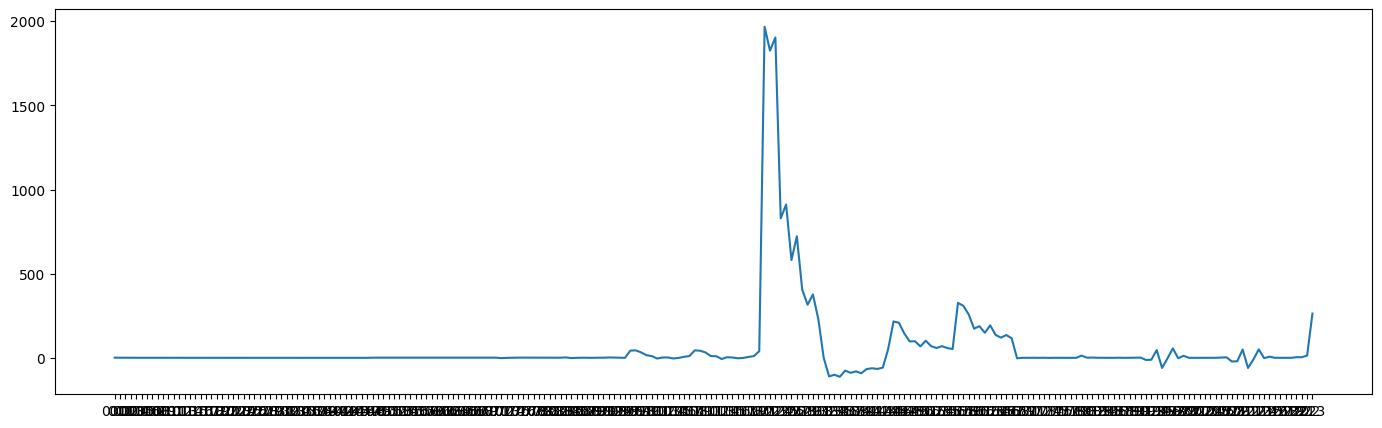

In [23]:
ipd.display(echonest['echonest', 'temporal_features'].head())
x = echonest.loc[2, ('echonest', 'temporal_features')]
plt.plot(x);

Lọc nhãn thể loại (`genre_top`) cho tập `small`, chuẩn bị dữ liệu để phân tích/trực quan hóa theo thể loại.

((2000, 2), (2000,))

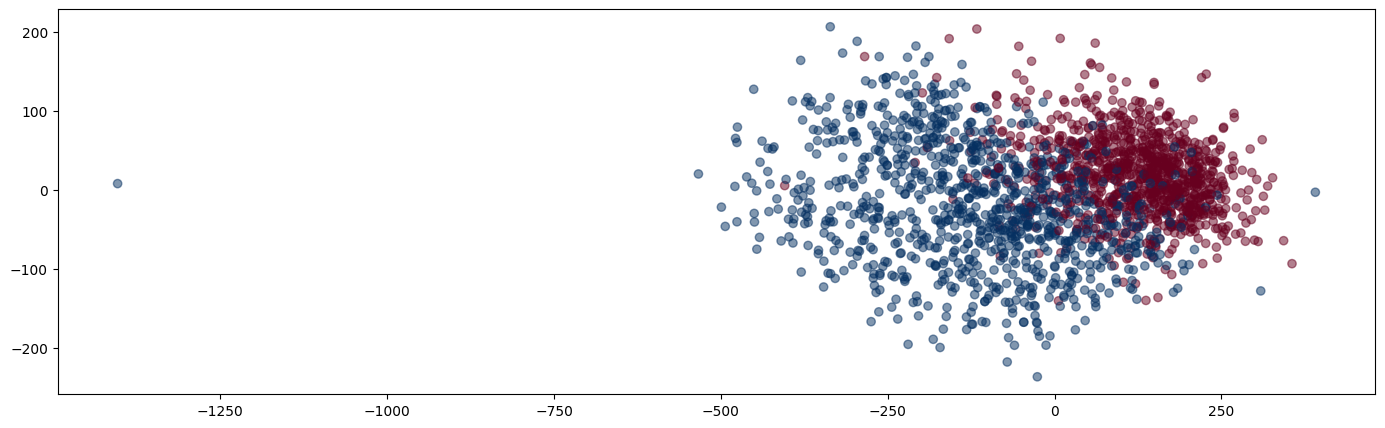

In [24]:
small = tracks['set', 'subset'] <= 'small'
genre1 = tracks['track', 'genre_top'] == 'Instrumental'
genre2 = tracks['track', 'genre_top'] == 'Hip-Hop'

X = features.loc[small & (genre1 | genre2), 'mfcc']
X = skl.decomposition.PCA(n_components=2).fit_transform(X)

y = tracks.loc[small & (genre1 | genre2), ('track', 'genre_top')]
y = skl.preprocessing.LabelEncoder().fit_transform(y)

plt.scatter(X[:,0], X[:,1], c=y, cmap='RdBu', alpha=0.5)
X.shape, y.shape

## 3. Xử lý & trực quan hóa âm thanh
Lấy đường dẫn file mp3 của 1 bài hát mẫu (track_id = 2) và load waveform (dạng sóng âm thanh thô) bằng `librosa.load()` để chuẩn bị vẽ và nghe thử.

In [25]:
filename = utils.get_audio_path(AUDIO_DIR, 2)
print('File: {}'.format(filename))

x, sr = librosa.load(filename, sr=None, mono=True)
print('Duration: {:.2f}s, {} samples'.format(x.shape[-1] / sr, x.size))

start, end = 7, 17
ipd.Audio(data=x[start*sr:end*sr], rate=sr)

File: /kaggle/working/fma/data/fma_small/000/000002.mp3
Duration: 29.98s, 1321967 samples


Nâng cấp `librosa` lên bản mới nhất — bản cũ trong requirements gốc của repo FMA đã lỗi thời, một số hàm (`waveplot`, `logamplitude`) không còn tồn tại ở các bản librosa hiện hành.

In [28]:
!pip install --upgrade librosa --break-system-packages

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.6/294.6 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 94.6 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 94.9 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.9/59.9 MB 32.5 MB/s eta 0:00:00:00:0100:01
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
  Attempting uninstall: llvmlite
    Found existing installation: llvmlite 0.43.0
    Uninstalling llvmlite-0.43.0:
      Successfully uninstalled llvmlite-0.43.0
  Attempting uninstall: numba
    Found existing installation: numba 0.60.0
    Uninstalling numba-0.60.0:
      Successfully uninstalled numba-0.60.0
  Attempting uninstall: librosa
    Found existing installation: librosa 0.11.0
    Uninstalling librosa-0.11.0:
      Successfully uninstalled librosa-0.11.0
ERROR: pip's dependency resolver doe

Vẽ dạng sóng (waveform) của bài hát mẫu bằng `librosa.display.waveshow()` (hàm thay thế cho `waveplot` đã bị xóa ở các bản librosa mới), kèm zoom vào đoạn giữa bài để nhìn chi tiết dạng sóng.

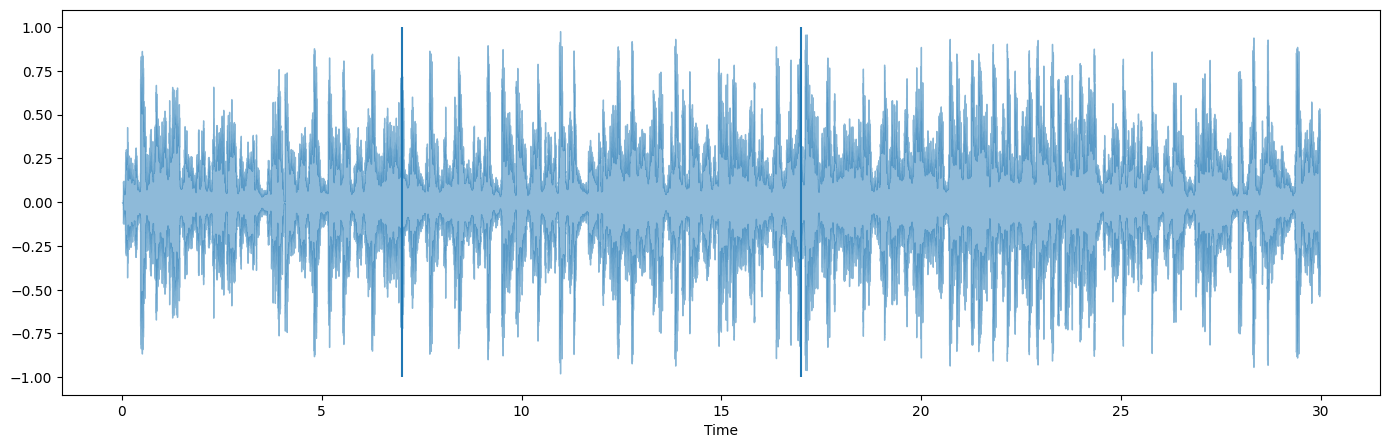

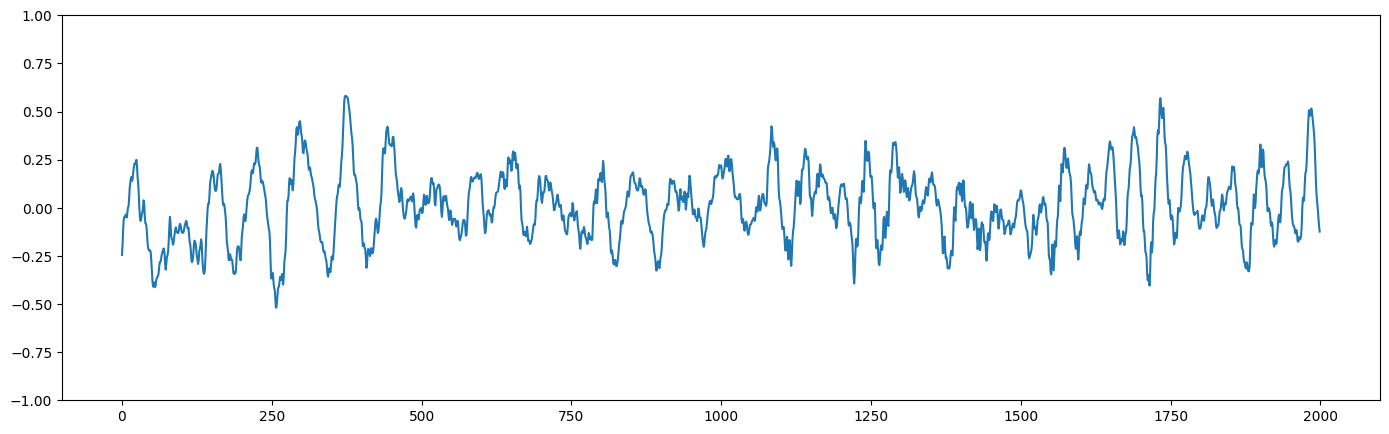

In [31]:
librosa.display.waveshow(x, sr=sr, alpha=0.5);
plt.vlines([start, end], -1, 1)

start = len(x) // 2
plt.figure()
plt.plot(x[start:start+2000])
plt.ylim((-1, 1));

Tính **Mel-spectrogram** (biểu diễn tần số theo thời gian, mô phỏng cách tai người cảm nhận âm thanh) từ STFT (Short-Time Fourier Transform), rồi chuyển sang thang decibel (`power_to_db`) và vẽ ra bằng `specshow`.

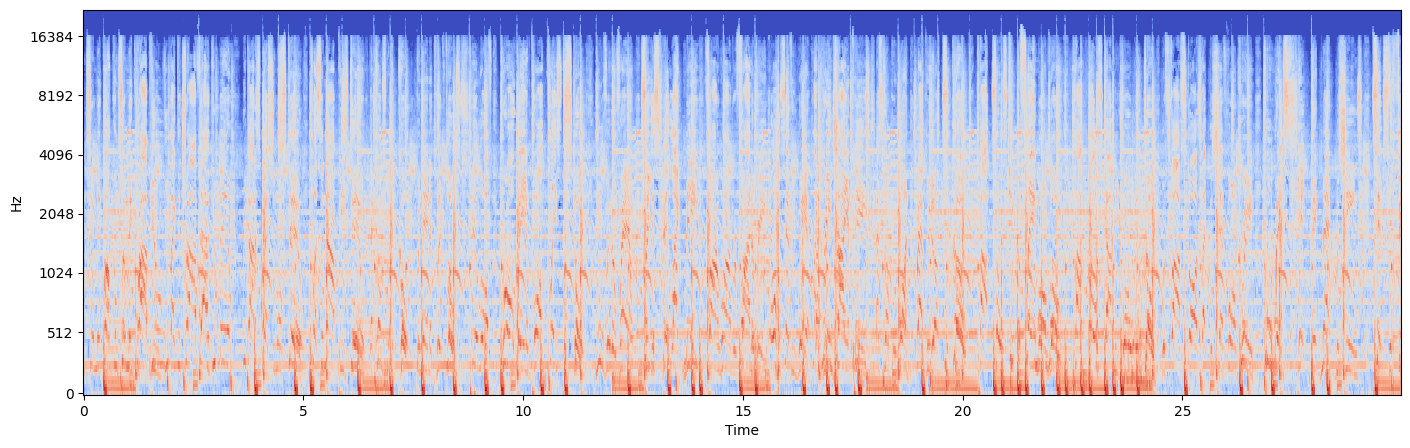

In [33]:
stft = np.abs(librosa.stft(x, n_fft=2048, hop_length=512))
mel = librosa.feature.melspectrogram(sr=sr, S=stft**2)
log_mel = librosa.power_to_db(mel)

librosa.display.specshow(log_mel, sr=sr, hop_length=512, x_axis='time', y_axis='mel');

Tính **MFCC** (Mel-Frequency Cepstral Coefficients) — đặc trưng âm thanh phổ biến nhất trong xử lý tín hiệu âm nhạc/giọng nói, rồi chuẩn hóa (standardize) để dùng cho các bước machine learning tiếp theo.

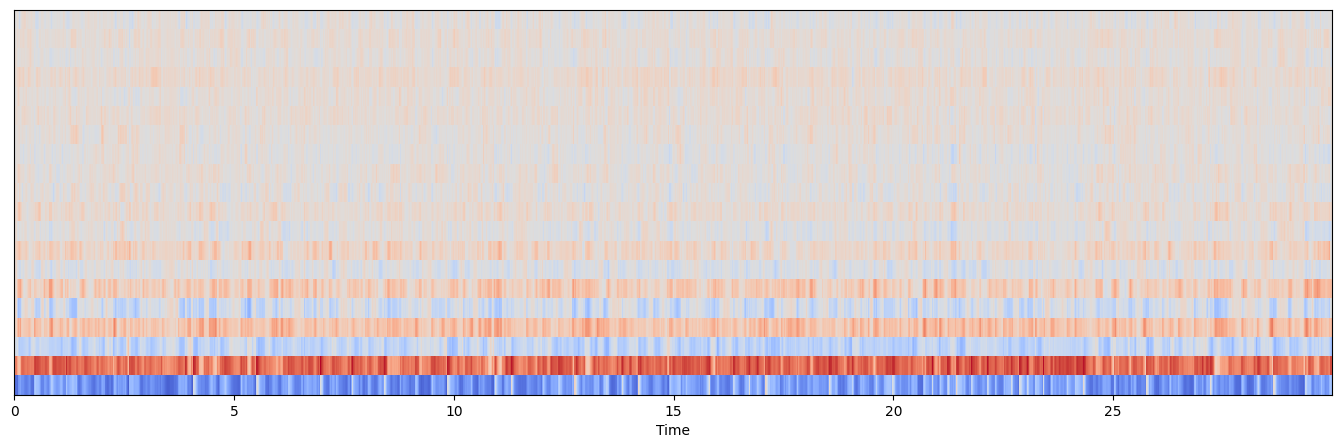

In [34]:
mfcc = librosa.feature.mfcc(S=librosa.power_to_db(mel), n_mfcc=20)
mfcc = skl.preprocessing.StandardScaler().fit_transform(mfcc)
librosa.display.specshow(mfcc, sr=sr, x_axis='time');

## 4. Xây dựng tập train/test cho bài toán phân loại thể loại
Chia dữ liệu tập `small` thành tập **train** và **test** dựa theo cột `split` có sẵn trong metadata, dùng đặc trưng MFCC làm input (`X`) và thể loại nhạc làm nhãn (`y`).

In [35]:
small = tracks['set', 'subset'] <= 'small'

train = tracks['set', 'split'] == 'training'
val = tracks['set', 'split'] == 'validation'
test = tracks['set', 'split'] == 'test'

y_train = tracks.loc[small & train, ('track', 'genre_top')]
y_test = tracks.loc[small & test, ('track', 'genre_top')]
X_train = features.loc[small & train, 'mfcc']
X_test = features.loc[small & test, 'mfcc']

print('{} training examples, {} testing examples'.format(y_train.size, y_test.size))
print('{} features, {} classes'.format(X_train.shape[1], np.unique(y_train).size))

6400 training examples, 800 testing examples
140 features, 8 classes


Xáo trộn (shuffle) tập train để đảm bảo dữ liệu không bị sắp xếp theo thứ tự cố định (tránh model học lệch), sau đó thử huấn luyện một mô hình phân loại (SVM) baseline để có mốc tham chiếu độ chính xác (Accuracy: 46.38%).

In [36]:
# Be sure training samples are shuffled.
X_train, y_train = skl.utils.shuffle(X_train, y_train, random_state=42)

# Standardize features by removing the mean and scaling to unit variance.
scaler = skl.preprocessing.StandardScaler(copy=False)
scaler.fit_transform(X_train)
scaler.transform(X_test)

# Support vector classification.
clf = skl.svm.SVC()
clf.fit(X_train, y_train)
score = clf.score(X_test, y_test)
print('Accuracy: {:.2%}'.format(score))

Accuracy: 46.38%


## 5. Gom cụm nhạc (Clustering) — So sánh nhiều thuật toán
Import các thuật toán clustering (`KMeans`, `AgglomerativeClustering`, `DBSCAN`, `GaussianMixture`, `SpectralClustering`) và các chỉ số đánh giá. Dùng **PCA** để giảm số chiều đặc trưng (140 → 30) giúp clustering chạy nhanh và ổn định hơn.

In [37]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.decomposition import PCA
import itertools

# Dùng dữ liệu đã chuẩn hóa (X_train đã qua StandardScaler ở cell trước)
X = X_train
y_true = y_train  # dùng để đối chiếu, KHÔNG dùng để fit model

# Giảm chiều bằng PCA để clustering nhanh và ổn định hơn (140 features hơi nhiều)
pca = PCA(n_components=30, random_state=42)
X_pca = pca.fit_transform(X)
print('Explained variance:', pca.explained_variance_ratio_.sum())

Explained variance: 0.7896598005248149


Cài lại (`--force-reinstall`) `numpy`, `scipy`, `scikit-learn` để khắc phục lỗi thư viện bị xung đột phiên bản sau khi upgrade librosa ở bước trước (lỗi `libscipy_openblas... No such file`). **Cần restart runtime sau bước này** để Python nạp lại đúng bản thư viện mới.

In [39]:
!pip install --force-reinstall numpy scipy scikit-learn --break-system-packages

  Using cached numpy-2.5.3-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 3.8 MB/s eta 0:00:00
Using cached numpy-2.5.3-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (16.7 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 59.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 112.4 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 474.0/474.0 kB 28.1 MB/s eta 0:00:00
  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 3.6.0
    Uninstalling threadpoolctl-3.6.0:
      Successfully uninstalled threadpoolctl-3.6.0
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.3
    Uninstalling numpy-2.5.3:
      Successfully uninstalled numpy-2.5.3
  Attempting uninstall: narwhals
    Found existing 

**Grid search** thủ công: thử nhiều cấu hình tham số khác nhau cho từng thuật toán clustering (KMeans, Agglomerative, DBSCAN, GaussianMixture, Spectral), đánh giá bằng:
- **Silhouette Score**: đo độ tách biệt/gọn của cụm, không cần nhãn thật.
- **ARI / NMI**: so sánh cụm tìm được với nhãn thể loại (genre) thật, chỉ dùng để kiểm chứng chứ không dùng để huấn luyện (clustering vẫn là unsupervised).

In [40]:
results = []

def evaluate(name, params, labels):
    # Bỏ qua nếu chỉ tạo ra 1 cụm hoặc toàn bộ là noise (DBSCAN)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    if n_clusters < 2:
        return
    sil = silhouette_score(X_pca, labels)
    ari = adjusted_rand_score(y_true, labels)
    nmi = normalized_mutual_info_score(y_true, labels)
    results.append({
        'model': name, 'params': params, 'n_clusters': n_clusters,
        'silhouette': sil, 'ARI': ari, 'NMI': nmi
    })

# ---- KMeans ----
for k in [4, 6, 8, 10, 12]:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X_pca)
    evaluate('KMeans', {'n_clusters': k}, labels)

# ---- Agglomerative Clustering ----
for k in [4, 6, 8, 10, 12]:
    for linkage in ['ward', 'average', 'complete']:
        model = AgglomerativeClustering(n_clusters=k, linkage=linkage)
        labels = model.fit_predict(X_pca)
        evaluate('Agglomerative', {'n_clusters': k, 'linkage': linkage}, labels)

# ---- DBSCAN ----
for eps in [0.5, 1.0, 1.5, 2.0, 3.0]:
    for min_samples in [5, 10, 20]:
        model = DBSCAN(eps=eps, min_samples=min_samples)
        labels = model.fit_predict(X_pca)
        evaluate('DBSCAN', {'eps': eps, 'min_samples': min_samples}, labels)

# ---- Gaussian Mixture ----
for k in [4, 6, 8, 10, 12]:
    for cov_type in ['full', 'diag', 'tied']:
        model = GaussianMixture(n_components=k, covariance_type=cov_type, random_state=42)
        labels = model.fit_predict(X_pca)
        evaluate('GaussianMixture', {'n_components': k, 'covariance_type': cov_type}, labels)

# ---- Spectral Clustering ----
for k in [4, 6, 8]:
    model = SpectralClustering(n_clusters=k, affinity='nearest_neighbors', random_state=42)
    labels = model.fit_predict(X_pca)
    evaluate('Spectral', {'n_clusters': k}, labels)

results_df = pd.DataFrame(results)
print(f'Tổng số cấu hình đã thử: {len(results_df)}')

Tổng số cấu hình đã thử: 38


Liệt kê **top 3 cấu hình tốt nhất** của mỗi thuật toán, xếp theo Silhouette Score và theo ARI, để so sánh model nào phù hợp nhất.

In [41]:
# Top 3 cấu hình tốt nhất theo silhouette score, cho mỗi model
best_by_silhouette = (results_df.sort_values('silhouette', ascending=False)
                                 .groupby('model').head(3)
                                 .sort_values('silhouette', ascending=False))
print("=== Top theo Silhouette Score ===")
print(best_by_silhouette.to_string(index=False))

print("\n=== Top theo ARI (so với genre thật) ===")
best_by_ari = (results_df.sort_values('ARI', ascending=False)
                          .groupby('model').head(3)
                          .sort_values('ARI', ascending=False))
print(best_by_ari.to_string(index=False))

=== Top theo Silhouette Score ===
          model                                         params  n_clusters  silhouette          ARI      NMI
  Agglomerative        {'n_clusters': 4, 'linkage': 'average'}           4    0.622415 2.932502e-07 0.000936
  Agglomerative        {'n_clusters': 6, 'linkage': 'average'}           6    0.592822 6.709651e-07 0.001868
  Agglomerative        {'n_clusters': 8, 'linkage': 'average'}           8    0.542628 3.178235e-06 0.003352
       Spectral                              {'n_clusters': 4}           4    0.109325 8.687744e-02 0.127025
         KMeans                              {'n_clusters': 4}           4    0.102321 8.303799e-02 0.108972
       Spectral                              {'n_clusters': 6}           6    0.100907 9.260156e-02 0.140744
GaussianMixture {'n_components': 4, 'covariance_type': 'tied'}           4    0.090709 2.719359e-02 0.093603
         KMeans                              {'n_clusters': 6}           6    0.079778 8.23401

Vẽ biểu đồ cột so sánh Silhouette Score và ARI cao nhất giữa các thuật toán clustering.

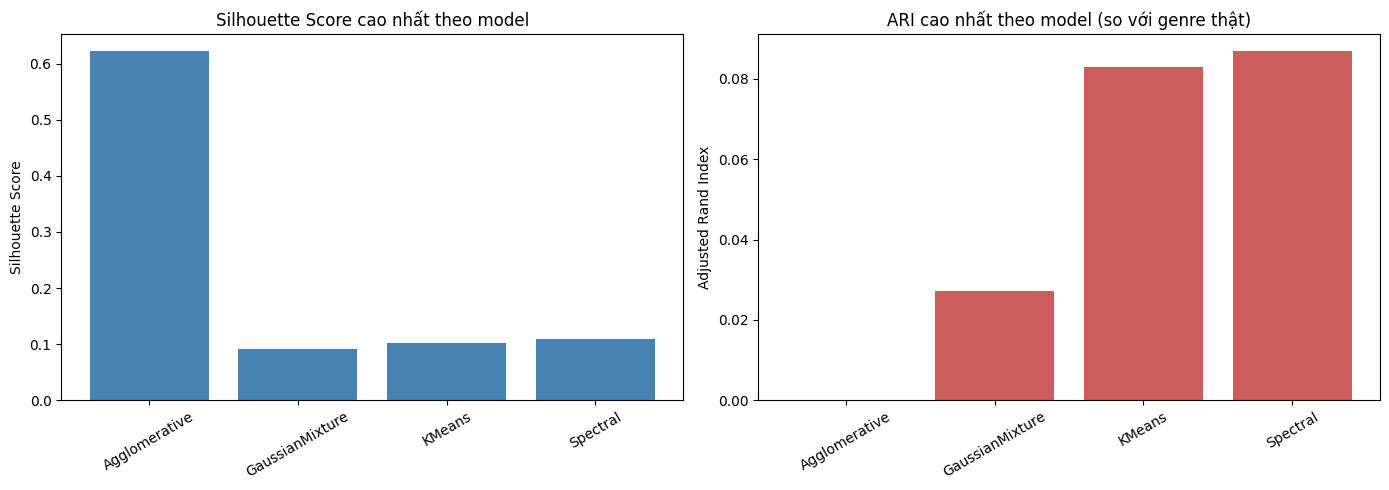

In [42]:
import matplotlib.pyplot as plt

best_per_model = results_df.loc[results_df.groupby('model')['silhouette'].idxmax()]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(best_per_model['model'], best_per_model['silhouette'], color='steelblue')
axes[0].set_title('Silhouette Score cao nhất theo model')
axes[0].set_ylabel('Silhouette Score')
axes[0].tick_params(axis='x', rotation=30)

axes[1].bar(best_per_model['model'], best_per_model['ARI'], color='indianred')
axes[1].set_title('ARI cao nhất theo model (so với genre thật)')
axes[1].set_ylabel('Adjusted Rand Index')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

⚠️ **Kiểm tra bẫy Silhouette Score**: in ra phân bố kích thước từng cụm để phát hiện trường hợp 1 thuật toán đạt Silhouette cao "ảo" chỉ vì dồn gần hết dữ liệu vào 1 cụm lớn duy nhất (điển hình là `AgglomerativeClustering` với `linkage='average'`), trong khi ARI của nó lại gần bằng 0 — tức là không phản ánh cấu trúc thể loại thật.

In [43]:
from collections import Counter

print("=== Kiểm tra phân bố kích thước cụm ===\n")

# Agglomerative với linkage='average' - nghi ngờ bị bẫy
for k in [4, 6, 8]:
    model = AgglomerativeClustering(n_clusters=k, linkage='average')
    labels = model.fit_predict(X_pca)
    counts = Counter(labels)
    sizes = sorted(counts.values(), reverse=True)
    print(f"Agglomerative (average, k={k}): {sizes}")

print()

# So sánh với KMeans và Spectral - để đối chiếu, cụm nên cân đối hơn
for k in [4, 6]:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X_pca)
    counts = Counter(labels)
    sizes = sorted(counts.values(), reverse=True)
    print(f"KMeans (k={k}): {sizes}")

for k in [4, 6]:
    model = SpectralClustering(n_clusters=k, affinity='nearest_neighbors', random_state=42)
    labels = model.fit_predict(X_pca)
    counts = Counter(labels)
    sizes = sorted(counts.values(), reverse=True)
    print(f"Spectral (k={k}): {sizes}")

=== Kiểm tra phân bố kích thước cụm ===

Agglomerative (average, k=4): [6397, 1, 1, 1]
Agglomerative (average, k=6): [6394, 2, 1, 1, 1, 1]
Agglomerative (average, k=8): [6388, 5, 2, 1, 1, 1, 1, 1]

KMeans (k=4): [2115, 1859, 1739, 687]
KMeans (k=6): [1591, 1384, 1228, 1133, 783, 281]
Spectral (k=4): [2520, 2130, 1734, 16]
Spectral (k=6): [2469, 1938, 1897, 64, 16, 16]


Chuyển nhãn thể loại dạng chữ (`Rock`, `Pop`...) sang dạng số bằng `LabelEncoder`, để có thể dùng làm giá trị màu (`c=...`) khi vẽ scatter plot.

In [45]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_true_encoded = le.fit_transform(y_true)

print(dict(zip(le.classes_, range(len(le.classes_)))))  # xem mapping tên -> số

{'Electronic': 0, 'Experimental': 1, 'Folk': 2, 'Hip-Hop': 3, 'Instrumental': 4, 'International': 5, 'Pop': 6, 'Rock': 7}


## 6. Trực quan hóa cụm bằng t-SNE (2D)
Giảm chiều dữ liệu xuống 2D bằng **t-SNE** (giữ cấu trúc cụm rõ hơn PCA), rồi vẽ 3 biểu đồ scatter cạnh nhau: **genre thật** vs **cụm KMeans** vs **cụm Spectral**, để so sánh trực quan bằng mắt xem cụm tìm được có khớp với thể loại nhạc thật hay không.

Đang chạy t-SNE, có thể mất 1-2 phút...


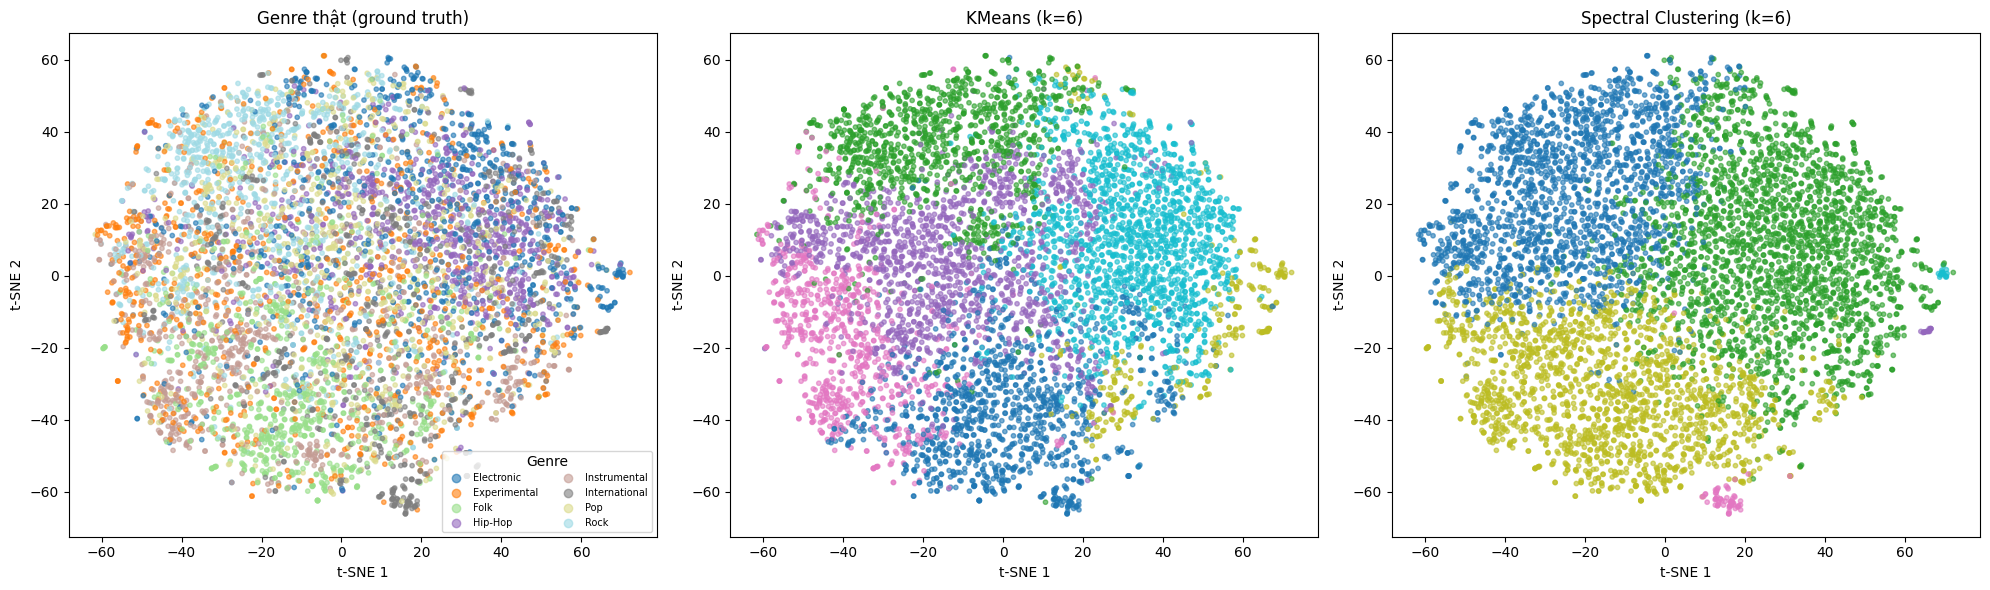

In [46]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Giảm về 2D bằng t-SNE để vẽ (t-SNE cho hình dạng cụm rõ hơn PCA 2D)
print("Đang chạy t-SNE, có thể mất 1-2 phút...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_pca)

# Lấy nhãn từ các model tốt nhất để so sánh
kmeans_labels = KMeans(n_clusters=6, n_init=10, random_state=42).fit_predict(X_pca)
spectral_labels = SpectralClustering(n_clusters=6, affinity='nearest_neighbors', random_state=42).fit_predict(X_pca)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Genre thật (ground truth) - dùng bản đã encode
scatter0 = axes[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_true_encoded, cmap='tab20', s=10, alpha=0.6)
axes[0].set_title('Genre thật (ground truth)')
axes[0].set_xlabel('t-SNE 1')
axes[0].set_ylabel('t-SNE 2')

# Custom legend hiển thị đúng tên genre thay vì số
handles, _ = scatter0.legend_elements(num=len(le.classes_))
axes[0].legend(handles, le.classes_, title="Genre", loc='best', fontsize=7, ncol=2)

# 2. KMeans clusters
scatter1 = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=kmeans_labels, cmap='tab10', s=10, alpha=0.6)
axes[1].set_title('KMeans (k=6)')
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')

# 3. Spectral clusters
scatter2 = axes[2].scatter(X_tsne[:, 0], X_tsne[:, 1], c=spectral_labels, cmap='tab10', s=10, alpha=0.6)
axes[2].set_title('Spectral Clustering (k=6)')
axes[2].set_xlabel('t-SNE 1')
axes[2].set_ylabel('t-SNE 2')

plt.tight_layout()
plt.savefig('clustering_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Trực quan hóa cụm bằng t-SNE (3D)
Tương tự bước trên nhưng giảm chiều xuống 3D để nhìn rõ hơn hình dạng phân bố của các cụm trong không gian đặc trưng. Lưu ý: t-SNE ở chế độ 3D chạy chậm hơn đáng kể so với 2D.

Đang chạy t-SNE 3D, có thể mất 2-3 phút...


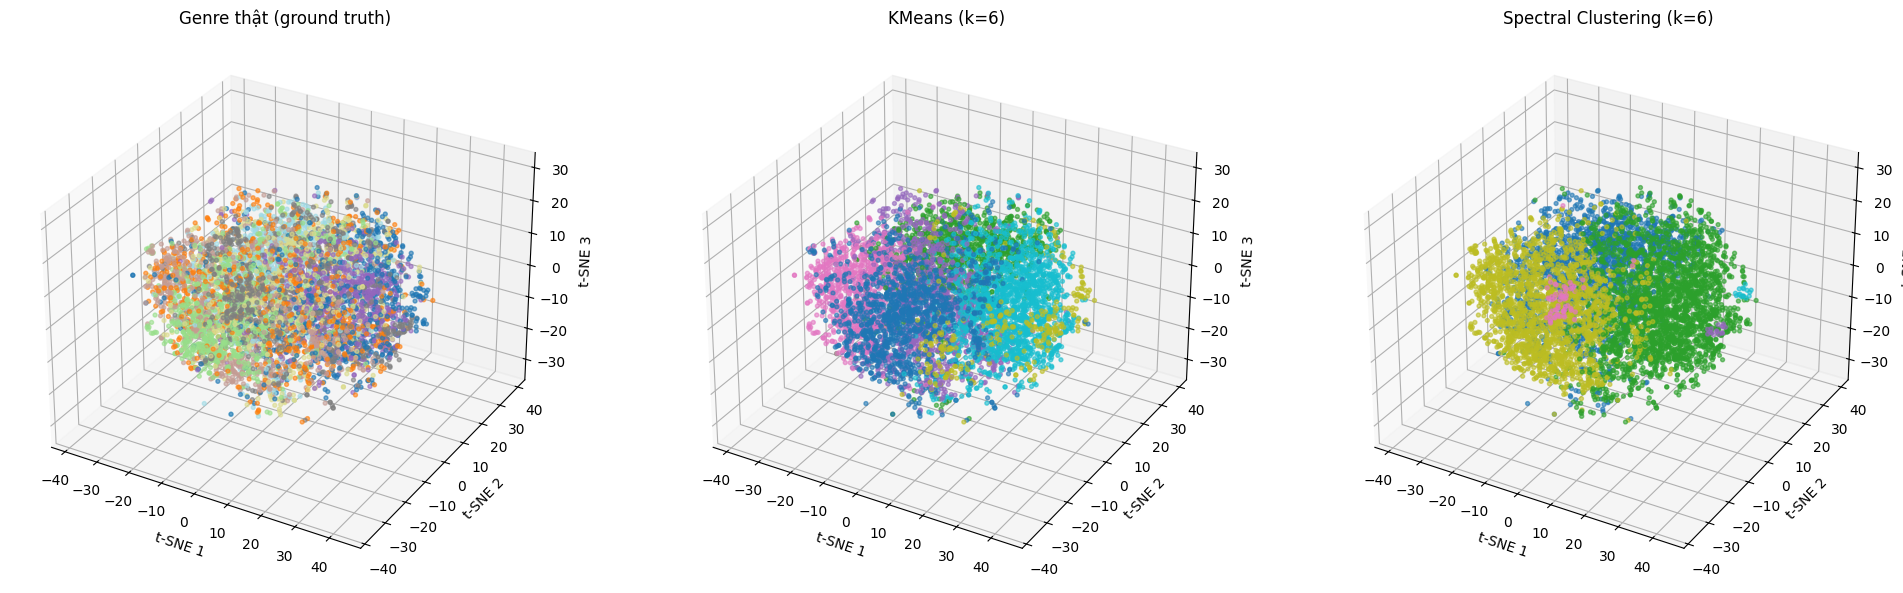

In [47]:
from sklearn.manifold import TSNE
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

print("Đang chạy t-SNE 3D, có thể mất 2-3 phút...")
tsne3d = TSNE(n_components=3, random_state=42, perplexity=30)
X_tsne_3d = tsne3d.fit_transform(X_pca)

kmeans_labels = KMeans(n_clusters=6, n_init=10, random_state=42).fit_predict(X_pca)
spectral_labels = SpectralClustering(n_clusters=6, affinity='nearest_neighbors', random_state=42).fit_predict(X_pca)

fig = plt.figure(figsize=(20, 6))

# 1. Genre thật
ax1 = fig.add_subplot(131, projection='3d')
sc1 = ax1.scatter(X_tsne_3d[:, 0], X_tsne_3d[:, 1], X_tsne_3d[:, 2],
                   c=y_true_encoded, cmap='tab20', s=8, alpha=0.6)
ax1.set_title('Genre thật (ground truth)')
ax1.set_xlabel('t-SNE 1'); ax1.set_ylabel('t-SNE 2'); ax1.set_zlabel('t-SNE 3')

# 2. KMeans
ax2 = fig.add_subplot(132, projection='3d')
ax2.scatter(X_tsne_3d[:, 0], X_tsne_3d[:, 1], X_tsne_3d[:, 2],
            c=kmeans_labels, cmap='tab10', s=8, alpha=0.6)
ax2.set_title('KMeans (k=6)')
ax2.set_xlabel('t-SNE 1'); ax2.set_ylabel('t-SNE 2'); ax2.set_zlabel('t-SNE 3')

# 3. Spectral
ax3 = fig.add_subplot(133, projection='3d')
ax3.scatter(X_tsne_3d[:, 0], X_tsne_3d[:, 1], X_tsne_3d[:, 2],
            c=spectral_labels, cmap='tab10', s=8, alpha=0.6)
ax3.set_title('Spectral Clustering (k=6)')
ax3.set_xlabel('t-SNE 1'); ax3.set_ylabel('t-SNE 2'); ax3.set_zlabel('t-SNE 3')

plt.tight_layout()
plt.savefig('clustering_comparison_3d.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Xây dựng hệ thống gợi ý nhạc (Recommendation)
Chọn **Spectral Clustering (k=6)** làm mô hình chính thức (vì phân cụm rõ ràng hơn qua quan sát trực quan ở bước trước). Gắn nhãn cụm (`cluster`) cho từng bài hát và ghép với thông tin thật (tên bài, nghệ sĩ, thể loại) từ metadata để dễ đối chiếu kết quả.

In [56]:
import pandas as pd
import numpy as np

# Train Spectral làm model chính (theo đánh giá của bạn là phân cụm rõ hơn)
final_model_labels = spectral_labels  # đã có sẵn từ cell trước (k=6)

# Map track_id -> cluster
track_ids = X_train.index
song_clusters = pd.Series(final_model_labels, index=track_ids, name='cluster')

# Load lại metadata gốc để lấy tên bài, nghệ sĩ, thể loại thật (dùng utils của repo fma)
tracks = utils.load('data/fma_metadata/tracks.csv')
tracks_small = tracks[tracks['set', 'subset'] <= 'small']

# Bảng tra cứu nhanh: track_id -> title, artist, genre
song_info = pd.DataFrame({
    'title': tracks_small['track', 'title'],
    'artist': tracks_small['artist', 'name'],
    'genre': tracks_small['track', 'genre_top']
})

# Gắn cluster vào bảng info luôn cho tiện
song_info = song_info.loc[song_clusters.index]
song_info['cluster'] = song_clusters

print(song_info.head(10))

                                    title               artist          genre  \
track_id                                                                        
59681                       Esches Chayil      Isra-Alien Band  International   
79087            Le Stanze Del Transistor           Bob Meanza   Experimental   
113305    Dios anda pedo (DJ Edwin Remix)       Los Margaritos           Rock   
131791                          N'iceland           Pranavibes   Instrumental   
3778                          Calor Calor     La Troba Kung-Fu  International   
85691               Finding The Butterfly  Alexander Turnquist           Folk   
124175                            Breeeze             Jelsonic   Instrumental   
62191                         Go digitale               Divans  International   
63908                   Death By Hangover                  Tab        Hip-Hop   
119582              A Good Note To End On       Nicholas Smith   Experimental   

          cluster  
track_i

Hàm **đoán thể loại chủ đạo**: nhận vào danh sách các bài hát người dùng đã nghe/thích trước đó (sample), xác định cụm xuất hiện nhiều nhất trong số đó, rồi tra ra thể loại thật chiếm ưu thế trong cụm đó để diễn giải kết quả bằng ngôn ngữ dễ hiểu (thay vì chỉ số cụm trừu tượng).

In [57]:
def predict_dominant_genre(sample_track_ids):
    """
    Nhận vào list các track_id user đã nghe/thích trước đó.
    Trả về: cluster chủ đạo + thể loại thật chiếm ưu thế trong cluster đó (để hiểu bằng ngôn ngữ người)
    """
    valid_ids = [tid for tid in sample_track_ids if tid in song_info.index]
    if not valid_ids:
        print("Không có track_id nào hợp lệ trong tập dữ liệu.")
        return None, None

    sample_df = song_info.loc[valid_ids]
    print("=== Các bài đã chọn (sample input) ===")
    print(sample_df[['title', 'artist', 'genre', 'cluster']].to_string())

    # Cluster xuất hiện nhiều nhất trong các bài đã pick
    dominant_cluster = sample_df['cluster'].mode()[0]

    # Thể loại thật chiếm ưu thế trong cluster đó (để diễn giải bằng ngôn ngữ người, không chỉ số cụm)
    cluster_members = song_info[song_info['cluster'] == dominant_cluster]
    dominant_genre = cluster_members['genre'].mode()[0]
    genre_distribution = cluster_members['genre'].value_counts(normalize=True).head(5)

    print(f"\n=== Kết quả đoán ===")
    print(f"Cluster chủ đạo: {dominant_cluster}")
    print(f"Thể loại chiếm ưu thế trong cluster này: {dominant_genre}")
    print(f"\nPhân bố thể loại trong cluster {dominant_cluster} (top 5):")
    print(genre_distribution)

    return dominant_cluster, dominant_genre

# Ví dụ: giả sử user đã nghe 3 bài Rock trước đó
sample_picks = [track_ids[5], track_ids[20], track_ids[35]]  # thay bằng track_id thật bạn muốn test
dominant_cluster, dominant_genre = predict_dominant_genre(sample_picks)

=== Các bài đã chọn (sample input) ===
                          title                 artist       genre  cluster
track_id                                                                   
85691     Finding The Butterfly    Alexander Turnquist        Folk        4
48456                       nez  AlexandreDavidGabriel         Pop        1
120471                   Sphere                   SPCZ  Electronic        0

=== Kết quả đoán ===
Cluster chủ đạo: 0
Thể loại chiếm ưu thế trong cluster này: Rock

Phân bố thể loại trong cluster 0 (top 5):
genre
Rock            0.311146
Pop             0.152735
Experimental    0.134159
Electronic      0.097523
Instrumental    0.095459
Name: proportion, dtype: float64


Hàm **gợi ý bài hát tiếp theo**: tính điểm trung tâm (centroid) đặc trưng của các bài đã nghe để đại diện cho "gu nghe nhạc" của người dùng, sau đó xếp hạng các bài còn lại trong cụm chủ đạo theo độ gần (khoảng cách Euclidean) với gu đó — trả về danh sách kèm tên bài, nghệ sĩ, thể loại và khoảng cách để đối chiếu độ hợp lý.

In [59]:
from sklearn.metrics.pairwise import euclidean_distances

def recommend_next_songs(sample_track_ids, n_recommend=8):
    dominant_cluster, dominant_genre = predict_dominant_genre(sample_track_ids)
    if dominant_cluster is None:
        return None

    # Lấy tất cả bài trong cluster chủ đạo, loại bỏ các bài đã nghe rồi
    candidates = song_info[song_info['cluster'] == dominant_cluster].index
    candidates = candidates.difference(sample_track_ids)

    # Tính centroid (điểm trung tâm) của các bài user đã thích, trong không gian feature
    sample_idx = [track_ids.get_loc(tid) for tid in sample_track_ids if tid in track_ids]
    user_taste_vector = X_pca[sample_idx].mean(axis=0).reshape(1, -1)

    # Xếp hạng các bài ứng viên theo độ gần với "gu nghe" của user
    candidate_idx = [track_ids.get_loc(tid) for tid in candidates]
    candidate_vecs = X_pca[candidate_idx]
    dists = euclidean_distances(user_taste_vector, candidate_vecs)[0]

    ranking = pd.Series(dists, index=candidates).sort_values().head(n_recommend)

    # Ghép với thông tin đầy đủ để đối chiếu
    result = song_info.loc[ranking.index].copy()
    result['distance'] = ranking.values
    result = result.sort_values('distance')

    print(f"\n=== Gợi ý {n_recommend} bài tiếp theo (thể loại chủ đạo: {dominant_genre}, cluster {dominant_cluster}) ===")
    print(result[['title', 'artist', 'genre', 'distance']].to_string())

    return result

# Chạy thử
recommendations = recommend_next_songs(sample_picks, n_recommend=8)

=== Các bài đã chọn (sample input) ===
                          title                 artist       genre  cluster
track_id                                                                   
85691     Finding The Butterfly    Alexander Turnquist        Folk        4
48456                       nez  AlexandreDavidGabriel         Pop        1
120471                   Sphere                   SPCZ  Electronic        0

=== Kết quả đoán ===
Cluster chủ đạo: 0
Thể loại chiếm ưu thế trong cluster này: Rock

Phân bố thể loại trong cluster 0 (top 5):
genre
Rock            0.311146
Pop             0.152735
Experimental    0.134159
Electronic      0.097523
Instrumental    0.095459
Name: proportion, dtype: float64

=== Gợi ý 8 bài tiếp theo (thể loại chủ đạo: Rock, cluster 0) ===
                                                      title                 artist          genre  distance
track_id                                                                                                   
8595

(Tùy chọn) Nghe thử trực tiếp một vài bài hát trong danh sách được gợi ý ngay trong notebook, để kiểm chứng bằng tai xem gợi ý có hợp lý không.

In [60]:
import IPython.display as ipd

def play_recommendations(recs_df, n_play=3):
    for tid in recs_df.index[:n_play]:
        row = song_info.loc[tid]
        print(f"Track {tid}: {row['title']} — {row['artist']} ({row['genre']})")
        filename = utils.get_audio_path(AUDIO_DIR, tid)
        display(ipd.Audio(filename))

play_recommendations(recommendations, n_play=3)

Track 85953: All I Am — Pete Galub (Pop)


Track 34511: Vilse (Slutet Cover) — Symfoniorkestern (Pop)


Track 121473: Duets — Satellite Ensemble (Instrumental)
